# Week 4 — Task 5: Gaussian smoothing + 3×3 Laplacian, compared with Sobel and Prewitt

> *5. 3×3 boyutunda Laplacian Çekirdeği ile kenarların tespitini yapınız. Filtreleri görüntü üzerinde çalıştırmadan önce Gauss filtresi ile görüntüyü hafif yumuşatınız. Sonuçlarını Sobel ve Prewitt ile kıyaslayan bir karşılaştırma dokümanı hazırlayınız.*

Same image and same light Gaussian (5×5, σ = 1) as Tasks 1–4. The comparison document is **[`LAPLACIAN_VS_SOBEL_PREWITT.md`](LAPLACIAN_VS_SOBEL_PREWITT.md)**; every number in it comes from this notebook.

Pipeline: **color → grayscale → Gaussian → Laplacian → zero crossings = edges**.

## 1. Setup

**On Colab with a GPU:** each notebook gets its own runtime, so the CUDA build from the Week 1 notebook is not automatically here. The next cell looks for it in this order: already installed at `/opt/opencv-cuda` → the Google Drive cache written by the Week 1 notebook (`USE_DRIVE = True`). If neither exists it simply uses the normal CPU-only OpenCV. **Run this cell before anything imports `cv2`.**

In [1]:
import os, sys, glob, subprocess

CUDA_PREFIX = "/opt/opencv-cuda"
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.isdir(f"{CUDA_PREFIX}/python"):
    has_gpu = subprocess.run("nvidia-smi", shell=True, capture_output=True).returncode == 0
    if has_gpu:
        from google.colab import drive
        drive.mount("/content/drive")
        pyver = f"{sys.version_info.major}.{sys.version_info.minor}"
        caches = sorted(glob.glob(f"/content/drive/MyDrive/opencv_cuda_cache/opencv-*-py{pyver}.tar.gz"))
        if caches:
            os.makedirs(CUDA_PREFIX, exist_ok=True)
            subprocess.run(["tar", "-xzf", caches[-1], "-C", CUDA_PREFIX], check=True)
            print("Restored CUDA OpenCV from", caches[-1])
        else:
            print("No Drive cache found → CPU only. Run week1/01_cuda_opencv_colab_setup.ipynb with USE_DRIVE = True first.")

if os.path.isdir(f"{CUDA_PREFIX}/python"):
    sys.path.insert(0, f"{CUDA_PREFIX}/python")   # take precedence over the CPU-only pip wheel
    print("Using CUDA build from", CUDA_PREFIX)

In [2]:
from pathlib import Path
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Works when run from the repo root, from week4/, or on Colab (downloads the image if missing)
HERE = Path("week4") if Path("week4/assets").exists() else Path(".")
IMG = HERE / "assets" / "rocket.jpg"
if not IMG.exists():
    import urllib.request
    IMG.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.25.2/skimage/data/rocket.jpg", IMG)
OUT = HERE / "results"
OUT.mkdir(exist_ok=True)
print("OpenCV", cv2.__version__, "| image:", IMG)

OpenCV 5.0.0 | image: assets/rocket.jpg


## 2. Grayscale and light Gaussian smoothing (identical to Tasks 1–4)

In [3]:
gray = cv2.cvtColor(cv2.imread(str(IMG)), cv2.COLOR_BGR2GRAY)
gray_f = gray.astype(np.float32)
KSIZE, SIGMA = (5, 5), 1.0
smooth = cv2.GaussianBlur(gray_f, KSIZE, SIGMA, borderType=cv2.BORDER_REFLECT_101)
print(gray.shape)

(427, 640)


## 3. The Laplacian kernel

Sobel and Prewitt estimate the **first** derivative (the gradient, a vector with x and y parts). The Laplacian is the **second** derivative, summed over both directions:

∇²I = ∂²I/∂x² + ∂²I/∂y²

The 1-D second difference is `[1 −2 1]` (= `I(x−1) − 2I(x) + I(x+1)`). Adding it in x and in y gives the standard 3×3 kernel. Adding the two diagonal directions as well gives the 8-neighbour version:

```
4-neighbour            8-neighbour
[0  1  0]              [1  1  1]
[1 -4  1]              [1 -8  1]
[0  1  0]              [1  1  1]
```

What this means for edges:

* **One kernel, no direction.** There is no x/y pair; the result is a single number per pixel, so it gives no edge direction. The continuous Laplacian treats all directions equally, but this tiny 3×3 version does so only roughly (measured in 5c).
* **An edge is a zero crossing, not a peak.** Across a step, the first derivative has a peak at the edge; the second derivative is positive on the dark side, negative on the bright side, and **crosses zero exactly at the edge**. So |∇²I| shows *two* lines per edge, and the edge itself lies between them.
* **Very noise-sensitive.** Differentiating twice amplifies noise even more than once — which is why Gaussian smoothing first matters most here. Gaussian + Laplacian together is the classic **LoG** (Laplacian of Gaussian, Marr–Hildreth) edge detector.

`cv2.Laplacian(img, ddepth, ksize=1)` uses exactly the 4-neighbour kernel. (Careful: `ksize=3` is **not** the 8-neighbour kernel above; it is `[[2 0 2], [0 −8 0], [2 0 2]]`.)

In [4]:
L4K = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)
L8K = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], np.float32)

L4 = cv2.filter2D(smooth, cv2.CV_32F, L4K, borderType=cv2.BORDER_REFLECT_101)
L8 = cv2.filter2D(smooth, cv2.CV_32F, L8K, borderType=cv2.BORDER_REFLECT_101)
print("max |filter2D(L4) − cv2.Laplacian(ksize=1)| =",
      float(np.abs(L4 - cv2.Laplacian(smooth, cv2.CV_32F, ksize=1, borderType=cv2.BORDER_REFLECT_101)).max()))
print("cv2.Laplacian ksize=3 kernel is [[2,0,2],[0,-8,0],[2,0,2]]:",
      np.allclose(cv2.Laplacian(np.pad(np.ones((1, 1), np.float32), 2), cv2.CV_32F, ksize=3, borderType=cv2.BORDER_CONSTANT)[1:4, 1:4],
                  np.array([[2, 0, 2], [0, -8, 0], [2, 0, 2]])))

# Paper check: a 10 → 50 step. Second difference: +40 on the dark side, −40 on the bright side, 0 elsewhere
step = np.array([[10, 10, 10, 50, 50, 50]] * 3, dtype=np.float32)
print(cv2.filter2D(step, cv2.CV_32F, L4K, borderType=cv2.BORDER_REPLICATE))

max |filter2D(L4) − cv2.Laplacian(ksize=1)| = 0.0
cv2.Laplacian ksize=3 kernel is [[2,0,2],[0,-8,0],[2,0,2]]: True
[[  0.   0.  40. -40.   0.   0.]
 [  0.   0.  40. -40.   0.   0.]
 [  0.   0.  40. -40.   0.   0.]]


The step lies between columns 2 and 3. The response is **+40** just before it, **−40** just after it and 0 elsewhere: the sign flips (zero crossing) exactly at the edge. Sobel would give one peak of 160 there instead.

## 4. From Laplacian to an edge map: zero crossings

A pixel is marked as an edge when the Laplacian changes sign between it and its right or lower neighbour, **and** the jump across zero is larger than a threshold `T`. Without the threshold, every tiny ripple of noise in flat areas also crosses zero. Of the two pixels on either side, the one closer to zero is marked, so the edge is 1 pixel thin.

In [5]:
def zero_crossings(L, T):
    e = np.zeros(L.shape, bool)
    pairs = [((slice(None), slice(None, -1)), (slice(None), slice(1, None))),     # right neighbour
             ((slice(None, -1), slice(None)), (slice(1, None), slice(None)))]     # lower neighbour
    for ia, ib in pairs:
        a, b = L[ia], L[ib]
        c = (a * b < 0) & (np.abs(a - b) > T)
        nearer_a = np.abs(a) <= np.abs(b)
        e[ia] |= c & nearer_a
        e[ib] |= c & ~nearer_a
    return e

T = 10.0
edges4, edges8 = zero_crossings(L4, T), zero_crossings(L8, 3 * T)   # 8-neighbour kernel has ~3× the gain
edges_noT = zero_crossings(L4, 0.0)
print(f"edge pixels: L4 with T={T:g}: {edges4.mean() * 100:.1f} %   L8 with T={3 * T:g}: {edges8.mean() * 100:.1f} %   "
      f"L4 with T=0: {edges_noT.mean() * 100:.1f} %")
for name, e in [("L4", edges4), ("L8", edges8)]:
    cv2.imwrite(str(OUT / f"task5_02_zero_crossings_{name}.png"), (e * 255).astype(np.uint8))

edge pixels: L4 with T=10: 4.5 %   L8 with T=30: 4.1 %   L4 with T=0: 40.4 %


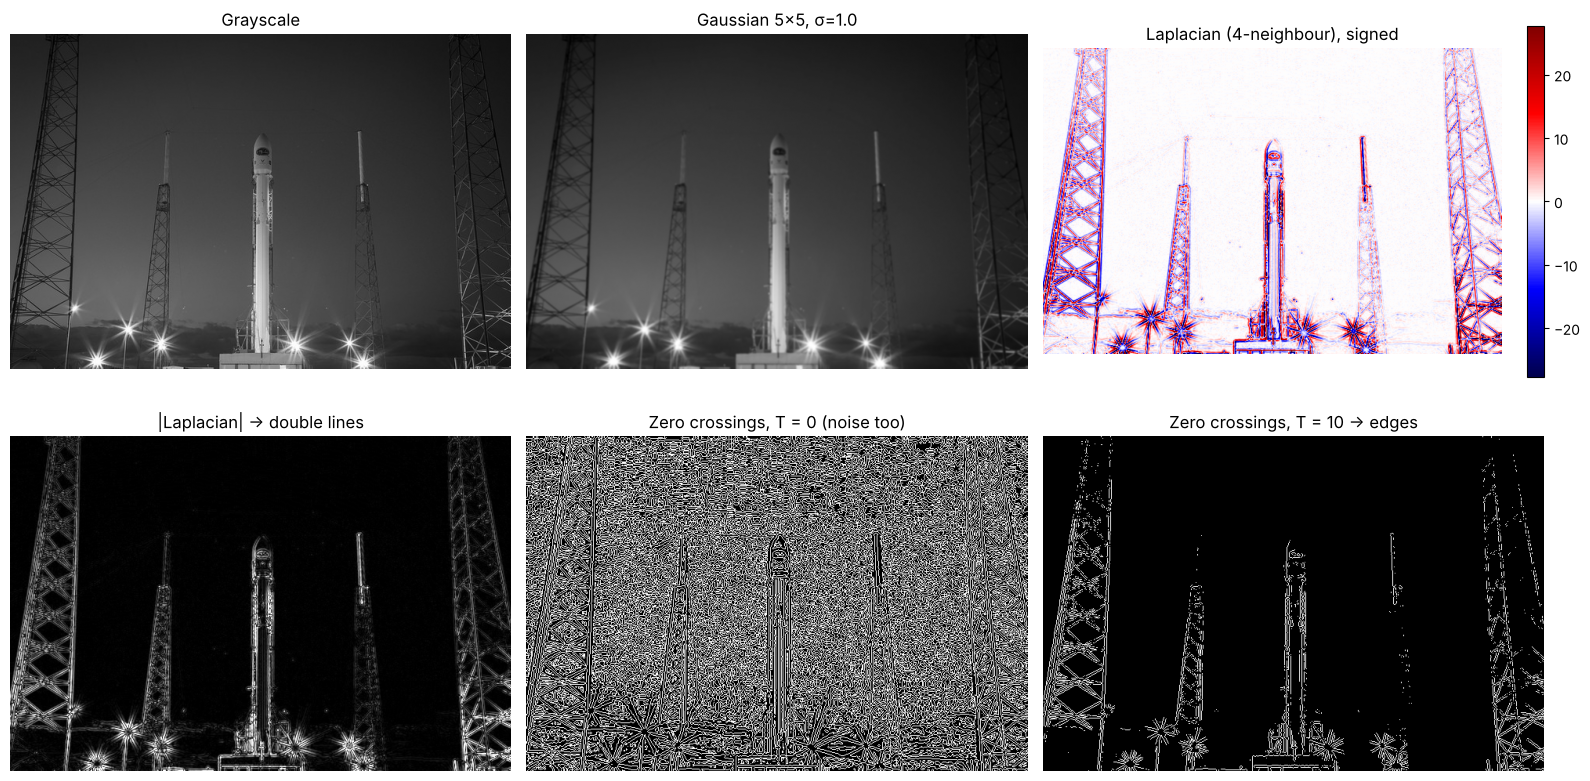

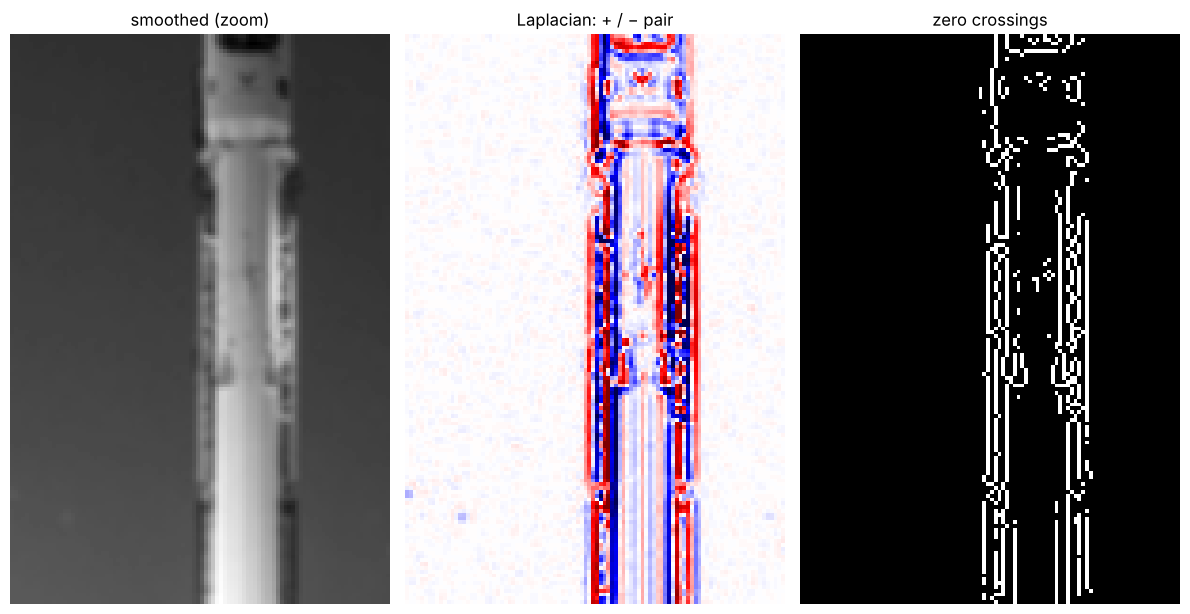

In [6]:
def to_u8(a):
    return cv2.normalize(np.abs(a), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
cv2.imwrite(str(OUT / "task5_01_laplacian_abs.png"), to_u8(L4))

lim = np.percentile(np.abs(L4), 99.5)
fig, ax = plt.subplots(2, 3, figsize=(16, 8.4))
ax[0, 0].imshow(gray, cmap="gray"); ax[0, 0].set_title("Grayscale")
ax[0, 1].imshow(smooth, cmap="gray"); ax[0, 1].set_title(f"Gaussian {KSIZE[0]}×{KSIZE[1]}, σ={SIGMA}")
im = ax[0, 2].imshow(L4, cmap="seismic", vmin=-lim, vmax=lim); ax[0, 2].set_title("Laplacian (4-neighbour), signed")
fig.colorbar(im, ax=ax[0, 2], fraction=0.035)
ax[1, 0].imshow(np.abs(L4), cmap="gray", vmax=lim); ax[1, 0].set_title("|Laplacian| → double lines")
ax[1, 1].imshow(edges_noT, cmap="gray"); ax[1, 1].set_title("Zero crossings, T = 0 (noise too)")
ax[1, 2].imshow(edges4, cmap="gray"); ax[1, 2].set_title(f"Zero crossings, T = {T:g} → edges")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task5_03_pipeline.png", dpi=110); plt.show()

# zoom on the rocket: double line in |L| vs single thin zero-crossing line
z = (slice(150, 300), slice(260, 360))
fig, ax = plt.subplots(1, 3, figsize=(12, 6.6))
ax[0].imshow(smooth[z], cmap="gray"); ax[0].set_title("smoothed (zoom)")
ax[1].imshow(L4[z], cmap="seismic", vmin=-lim, vmax=lim); ax[1].set_title("Laplacian: + / − pair")
ax[2].imshow(edges4[z], cmap="gray"); ax[2].set_title("zero crossings")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task5_04_zoom_double_line.png", dpi=110); plt.show()

## 5. Comparison with Sobel and Prewitt

### 5a. Side by side

For a fair edge map, Sobel and Prewitt magnitudes are thresholded so that they keep the **same number of edge pixels** as the Laplacian zero crossings. That way the difference is only *where* and *how thick* the edges are.

Prewitt (threshold)        edge pixels  4.53 %   mean line width ≈ 3.64 px
Sobel (threshold)          edge pixels  4.53 %   mean line width ≈ 3.57 px
Laplacian zero crossings   edge pixels  4.53 %   mean line width ≈ 1.45 px


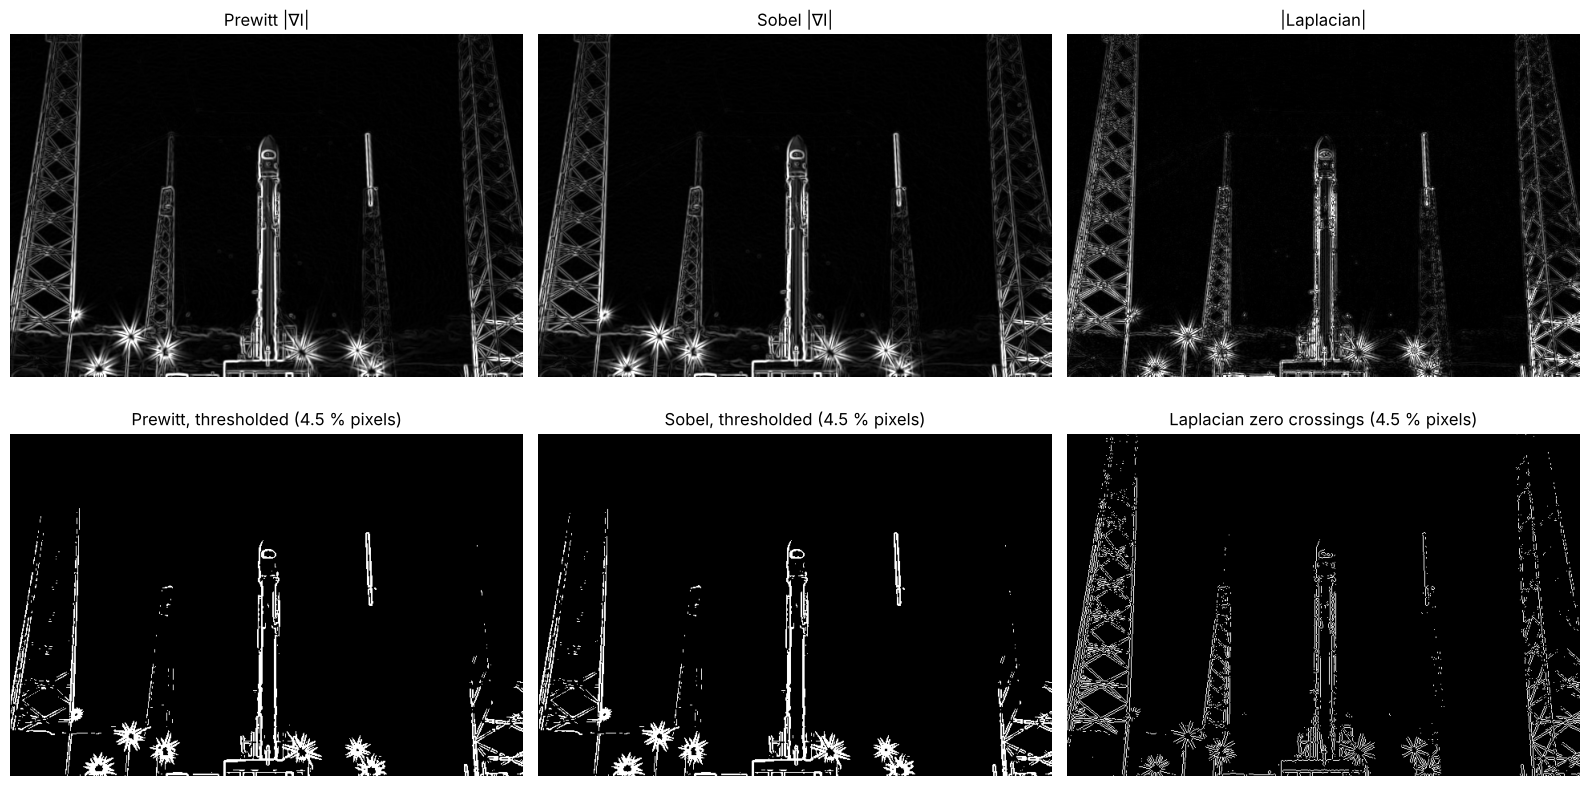

In [7]:
def grad_mag(img, k):
    return cv2.magnitude(cv2.filter2D(img, cv2.CV_32F, k), cv2.filter2D(img, cv2.CV_32F, k.T.copy()))

PK = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
SK = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
mag_p, mag_s = grad_mag(smooth, PK), grad_mag(smooth, SK)
frac = edges4.mean()
edges_p = mag_p > np.quantile(mag_p, 1 - frac)
edges_s = mag_s > np.quantile(mag_s, 1 - frac)

def thickness(e):
    # average run length of edge pixels along rows and columns (≈ line width in pixels)
    runs = []
    for arr in (e, e.T):
        d = np.diff(np.pad(arr.astype(np.int8), ((0, 0), (1, 1))), axis=1)
        runs.append((np.where(d == -1)[1] - np.where(d == 1)[1]))
    return float(np.mean(np.concatenate(runs)))

for name, e in [("Prewitt (threshold)", edges_p), ("Sobel (threshold)", edges_s), ("Laplacian zero crossings", edges4)]:
    print(f"{name:26s} edge pixels {e.mean() * 100:5.2f} %   mean line width ≈ {thickness(e):.2f} px")

fig, ax = plt.subplots(2, 3, figsize=(16, 8.4))
for a, img, t in [(ax[0, 0], mag_p, "Prewitt |∇I|"), (ax[0, 1], mag_s, "Sobel |∇I|"), (ax[0, 2], np.abs(L4), "|Laplacian|")]:
    a.imshow(img, cmap="gray", vmax=np.percentile(img, 99.5)); a.set_title(t)
for a, e, t in [(ax[1, 0], edges_p, "Prewitt, thresholded"), (ax[1, 1], edges_s, "Sobel, thresholded"),
                (ax[1, 2], edges4, "Laplacian zero crossings")]:
    a.imshow(e, cmap="gray"); a.set_title(f"{t} ({e.mean() * 100:.1f} % pixels)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task5_05_compare_sobel_prewitt_laplacian.png", dpi=110); plt.show()

### 5b. Noise

Same test as before: edge/noise = 99.5th percentile of |response| ÷ mean |response| in a flat sky patch. For the Laplacian the absolute value is used.

input                 Prewitt        Sobel  Laplacian-4  Laplacian-8
clean, no blur           21.9         21.6         21.1         21.8
clean, Gauss             23.5         23.3         21.5         21.9
noisy, no blur            5.8          5.7          4.0          4.4
noisy, Gauss              8.4          8.2          6.5          6.8


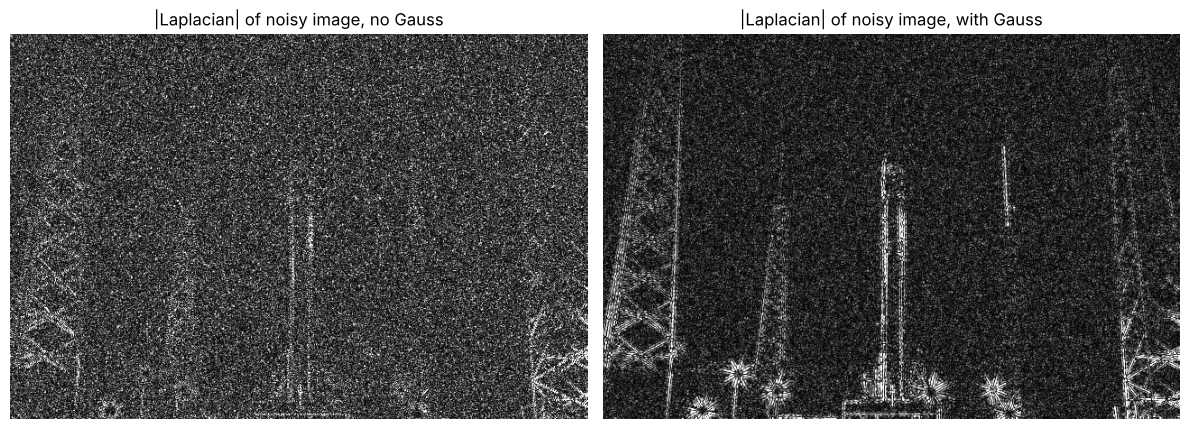

In [8]:
rng = np.random.default_rng(42)
noisy = np.clip(gray_f + rng.normal(0, 15, gray_f.shape), 0, 255).astype(np.float32)
sky = (slice(10, 110), slice(10, 160))
ops = {"Prewitt": lambda i: grad_mag(i, PK), "Sobel": lambda i: grad_mag(i, SK),
       "Laplacian-4": lambda i: np.abs(cv2.filter2D(i, cv2.CV_32F, L4K)),
       "Laplacian-8": lambda i: np.abs(cv2.filter2D(i, cv2.CV_32F, L8K))}
print(f"{'input':16s}" + "".join(f"{n:>13s}" for n in ops))
for label, img in [("clean, no blur", gray_f), ("clean, Gauss", smooth),
                   ("noisy, no blur", noisy), ("noisy, Gauss", cv2.GaussianBlur(noisy, KSIZE, SIGMA))]:
    vals = []
    for f in ops.values():
        r = f(img); vals.append(np.percentile(r, 99.5) / r[sky].mean())
    print(f"{label:16s}" + "".join(f"{v:13.1f}" for v in vals))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ln = np.abs(cv2.filter2D(noisy, cv2.CV_32F, L4K)); lg = np.abs(cv2.filter2D(cv2.GaussianBlur(noisy, KSIZE, SIGMA), cv2.CV_32F, L4K))
ax[0].imshow(ln, cmap="gray", vmax=np.percentile(ln, 99.5)); ax[0].set_title("|Laplacian| of noisy image, no Gauss")
ax[1].imshow(lg, cmap="gray", vmax=np.percentile(lg, 99.5)); ax[1].set_title("|Laplacian| of noisy image, with Gauss")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task5_06_noise.png", dpi=110); plt.show()

### 5c. Direction and edge position on a perfect circle

As in Task 4: an anti-aliased disc (radius 80 px), same Gaussian, sampled along 360 rays across its edge.

* **Direction dependence:** Sobel/Prewitt → peak of |∇I| on each ray; Laplacian → the size of its +/− swing (max − min) on each ray. Spread = (max − min)/mean over all directions; lower is better.
* **Edge position:** gradient → radius of the peak; Laplacian → radius of the zero crossing. The disc edge is at r = 80.

operator      direction spread  edge radius (true 80)
Prewitt                 11.6 %    mean  79.99, range 79.86–80.12
Sobel                    9.2 %    mean  79.99, range 79.88–80.12
Laplacian-4             17.9 %    mean  80.01, range 79.88–80.13
Laplacian-8             17.2 %    mean  80.01, range 79.89–80.12


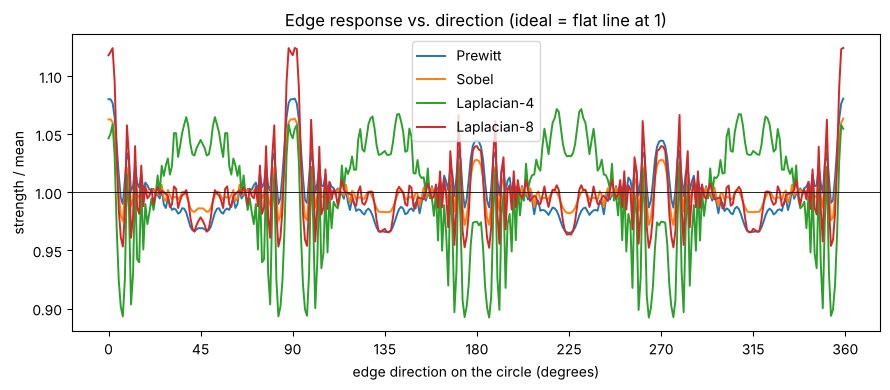

In [9]:
N, R, SS = 256, 80, 8
big = np.zeros((N * SS, N * SS), np.uint8)
cv2.circle(big, (N * SS // 2, N * SS // 2), R * SS, 255, -1)
disc = cv2.GaussianBlur(cv2.resize(big, (N, N), interpolation=cv2.INTER_AREA).astype(np.float32), KSIZE, SIGMA)

c = (N - 1) / 2
theta = np.arange(0, 360, 1.0)
radii = np.arange(R - 5, R + 5, 0.02)
T_, RR = np.meshgrid(np.radians(theta), radii, indexing="ij")
mapx, mapy = (c + RR * np.cos(T_)).astype(np.float32), (c + RR * np.sin(T_)).astype(np.float32)
ray = lambda a: cv2.remap(a, mapx, mapy, cv2.INTER_CUBIC)

curves, rows = {}, []
for name, k in [("Prewitt", PK), ("Sobel", SK)]:
    s = ray(grad_mag(disc, k))
    strength, pos = s.max(axis=1), radii[s.argmax(axis=1)]
    curves[name] = strength; rows.append((name, strength, pos))
for name, k in [("Laplacian-4", L4K), ("Laplacian-8", L8K)]:
    s = ray(cv2.filter2D(disc, cv2.CV_32F, k))
    strength = s.max(axis=1) - s.min(axis=1)
    # going outward along a ray: just inside the bright disc L has its minimum (< 0), just outside
    # its maximum (> 0); the edge is the − → + zero crossing between those two extremes
    imin, imax = s.argmin(axis=1), s.argmax(axis=1)
    j = np.arange(s.shape[1] - 1)[None, :]
    cross = (s[:, :-1] < 0) & (s[:, 1:] >= 0) & (j >= imin[:, None]) & (j < imax[:, None])
    assert cross.any(axis=1).all()
    i = np.argmax(cross, axis=1)
    s0, s1 = s[np.arange(len(theta)), i], s[np.arange(len(theta)), i + 1]
    pos = radii[i] + (radii[1] - radii[0]) * (-s0 / (s1 - s0))   # linear interpolation of the zero
    curves[name] = strength; rows.append((name, strength, pos))

print(f"{'operator':12s} {'direction spread':>17s} {'edge radius (true 80)':>22s}")
for name, strength, pos in rows:
    print(f"{name:12s} {(strength.max() - strength.min()) / strength.mean() * 100:15.1f} % "
          f"   mean {pos.mean():6.2f}, range {pos.min():.2f}–{pos.max():.2f}")

plt.figure(figsize=(9, 4))
for name, s in curves.items():
    plt.plot(theta, s / s.mean(), lw=1.4, label=name)
plt.axhline(1, color="k", lw=0.6); plt.xticks(range(0, 361, 45))
plt.xlabel("edge direction on the circle (degrees)"); plt.ylabel("strength / mean"); plt.legend()
plt.title("Edge response vs. direction (ideal = flat line at 1)")
plt.tight_layout(); plt.savefig(OUT / "task5_07_direction_test.png", dpi=110); plt.show()

### 5d. Speed (CPU, 640×427, including the zero-crossing step for the Laplacian)

In [10]:
def bench(fn, n=200):
    fn(); t = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - t) / n * 1e3

print(f"Prewitt |∇I|                 : {bench(lambda: grad_mag(smooth, PK)):.3f} ms")
print(f"Sobel   |∇I|                 : {bench(lambda: grad_mag(smooth, SK)):.3f} ms")
print(f"Laplacian (filter only)      : {bench(lambda: cv2.filter2D(smooth, cv2.CV_32F, L4K)):.3f} ms")
print(f"Laplacian + zero crossings   : {bench(lambda: zero_crossings(cv2.filter2D(smooth, cv2.CV_32F, L4K), T)):.3f} ms")

Prewitt |∇I|                 : 0.470 ms
Sobel   |∇I|                 : 0.430 ms
Laplacian (filter only)      : 0.117 ms


Laplacian + zero crossings   : 1.986 ms


## 6. Same pipeline on the GPU (OpenCV CUDA)

Runs only if `cv2.cuda` reports a device (see `week1/`). `cv2.cuda.createLaplacianFilter(..., ksize=1)` is the 4-neighbour kernel; it is compared with the CPU result.

In [11]:
has_cuda = hasattr(cv2, "cuda") and cv2.cuda.getCudaEnabledDeviceCount() > 0
print("CUDA devices visible to OpenCV:", cv2.cuda.getCudaEnabledDeviceCount() if hasattr(cv2, "cuda") else 0)
if not has_cuda:
    print("No CUDA build / GPU → skipped. Run week1/01_cuda_opencv_colab_setup.ipynb on a Colab GPU runtime first.")
else:
    gauss_gpu = cv2.cuda.createGaussianFilter(cv2.CV_32FC1, cv2.CV_32FC1, KSIZE, SIGMA)
    lap_gpu = cv2.cuda.createLaplacianFilter(cv2.CV_32FC1, cv2.CV_32FC1, ksize=1)

    def gpu_pipeline(img):
        g = cv2.cuda.GpuMat(); g.upload(img)
        return lap_gpu.apply(gauss_gpu.apply(g)).download()

    out = gpu_pipeline(gray_f)
    d = np.abs(out - L4)
    print(f"max |GPU − CPU| = {d.max():.4f}   (mean {d.mean():.6f})")

    big = cv2.resize(gray_f, (3840, 2160))
    cpu = lambda img: cv2.filter2D(cv2.GaussianBlur(img, KSIZE, SIGMA), cv2.CV_32F, L4K)
    for name, img in [("640×427", gray_f), ("3840×2160", big)]:
        print(f"{name:10s}  CPU {bench(lambda: cpu(img), 50):7.2f} ms   GPU (incl. upload/download) {bench(lambda: gpu_pipeline(img), 50):7.2f} ms")

CUDA devices visible to OpenCV: 0
No CUDA build / GPU → skipped. Run week1/01_cuda_opencv_colab_setup.ipynb on a Colab GPU runtime first.
